Dataset:
    Study_Hours  Attendance  Previous_Marks  Final_Marks
0             2          60              50           55
1             3          65              55           60
2             4          70              60           65
3             5          75              65           70
4             6          80              70           75
5             7          85              75           80
6             8          90              80           85
7             9          95              85           90
8             4          80              65           70
9             6          70              75           75
10            3          70              55           60
11            8          85              90           90

 Linear Regression
MSE: 0.6666666666666666
R2 Score: 0.9907692307692307

 Ridge Regression
MSE: 1.185751777196298
R2 Score: 0.9835818984695898

 Lasso Regression
MSE: 4.353872149596653
R2 Score: 0.9397156163902002

Linear Coefficients: [2.         1

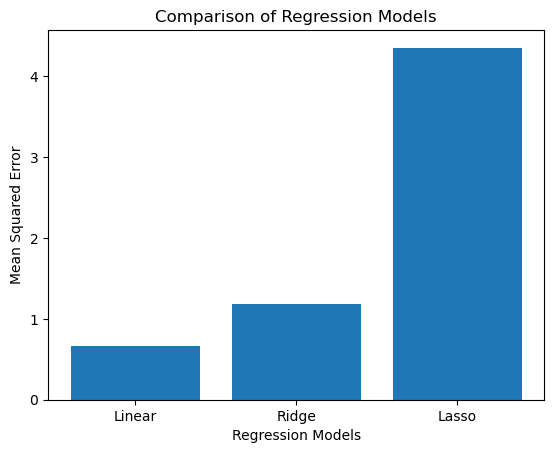

In [1]:

# Practical 4: Regression with Regularization

# Step 1: Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Create dataset
data = {
    'Study_Hours': [2, 3, 4, 5, 6, 7, 8, 9, 4, 6, 3, 8],
    'Attendance': [60, 65, 70, 75, 80, 85, 90, 95, 80, 70, 70, 85],
    'Previous_Marks': [50, 55, 60, 65, 70, 75, 80, 85, 65, 75, 55, 90],
    'Final_Marks': [55, 60, 65, 70, 75, 80, 85, 90, 70, 75, 60, 90]
}

df = pd.DataFrame(data)

print("Dataset:")
print(df)

# Step 3: Separate input and output
X = df[['Study_Hours', 'Attendance', 'Previous_Marks']]
y = df['Final_Marks']

# Step 4: Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

# Step 5: Standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Step 6: Create models
linear = LinearRegression()
ridge = Ridge(alpha=1.0)
lasso = Lasso(alpha=1.0, max_iter=10000)

# Step 7: Train models
linear.fit(X_train_scaled, y_train)
ridge.fit(X_train_scaled, y_train)
lasso.fit(X_train_scaled, y_train)

# Step 8: Make predictions
linear_pred = linear.predict(X_test_scaled)
ridge_pred = ridge.predict(X_test_scaled)
lasso_pred = lasso.predict(X_test_scaled)

# Step 9: Evaluate models
models = {
    "Linear Regression": linear_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred
}

for name, predictions in models.items():
    print("\n", name)
    print("MSE:", mean_squared_error(y_test, predictions))
    print("R2 Score:", r2_score(y_test, predictions))

# Step 10: Display coefficients
print("\nLinear Coefficients:", linear.coef_)
print("Ridge Coefficients:", ridge.coef_)
print("Lasso Coefficients:", lasso.coef_)

# Step 11: Compare model performance
mse_values = [
    mean_squared_error(y_test, linear_pred),
    mean_squared_error(y_test, ridge_pred),
    mean_squared_error(y_test, lasso_pred)
]

plt.bar(
    ["Linear", "Ridge", "Lasso"],
    mse_values
)

plt.xlabel("Regression Models")
plt.ylabel("Mean Squared Error")
plt.title("Comparison of Regression Models")
plt.show()
